# Support Ticket Classification & Prioritization

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import nltk 
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

In [9]:
SUBJECT_COL = "Ticket Subject"
TEXT_COL = "Ticket Description"
CATEGORY_COL = "Ticket Type"
PRIORITY_COL = "Ticket Priority"
TEST_SIZE = 0.2
RANDOM_STATE = 42
USE_RULES = True

In [10]:
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

try: 
    STOP_WORDS = set(stopwords.words("english"))
except Exception:
    STOP_WORDS = set(ENGLISH_STOP_WORDS)

KEEP_WORDS = {"no", "not" , "nor", "cannot", "never", "against"}  
STOP_WORDS = STOP_WORDS - KEEP_WORDS


try:
    lemmatizer = WordNetLemmatizer()
    lemmatizer.lemmatize("tests")
    lemmatize = lemmatizer.lemmatize
    print("NLTK lemmatizer: OK")

except Exception:
    lemmatize = lambda w: w 
    print("wordNet nhi mil rha ")

tokenizer = RegexpTokenizer(r"[a-z]+")

NLTK lemmatizer: OK


In [11]:
df = pd.read_csv("data/customer_support_tickets.csv", encoding="utf-8", encoding_errors = "replace")

print(df.shape)
print(df.columns)
df.head()

(8469, 17)
Index(['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age',
       'Customer Gender', 'Product Purchased', 'Date of Purchase',
       'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status',
       'Resolution', 'Ticket Priority', 'Ticket Channel',
       'First Response Time', 'Time to Resolution',
       'Customer Satisfaction Rating'],
      dtype='str')


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [12]:
needed = [c for c in [SUBJECT_COL, TEXT_COL, CATEGORY_COL, PRIORITY_COL] if c ]
missing_cols = [c for c in needed if c not in df.columns]

In [13]:
rows_before = len(df)

data = df.drop_duplicates()[needed].copy()
data = data.dropna(subset=[TEXT_COL, CATEGORY_COL, PRIORITY_COL])
data[PRIORITY_COL] = data[PRIORITY_COL].astype(str).str.strip().str.title()
data[PRIORITY_COL] = data[PRIORITY_COL].replace({"Critical" : "High", "Urgent": "High", "NOrmal" : "Medium"})
data = data[data[PRIORITY_COL].isin(["High", "Medium", "Low"])]

data[CATEGORY_COL] =  data[CATEGORY_COL].astype(str).str.strip()

In [14]:
def join_text(row):
    parts = [row[TEXT_COL]]
    if SUBJECT_COL: 
        parts.insert(0, row[SUBJECT_COL] if pd.notna(row[SUBJECT_COL]) else "")
    return " ".join(str(p) for p in parts)

data["raw_text"] = data.apply(join_text, axis=1)
data["raw_text"] = data["raw_text"].str.replace(r"\{[^}]*\}", " ", regex=True)
data["raw_text"] = data["raw_text"].str.replace(r"\s+", " ", regex=True)
data = data[data["raw_text"].str.len() > 0].reset_index(drop=True)

print(f"Rows before: {rows_before} | after cleaning: {len(data)} | removed: {rows_before - len(data)}")
print("\nCategory counts: ")
print(data[CATEGORY_COL].value_counts())
print("\nPriority counts:")
print(data[PRIORITY_COL].value_counts())

Rows before: 8469 | after cleaning: 8469 | removed: 0

Category counts: 
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Priority counts:
Ticket Priority
High      4214
Medium    2192
Low       2063
Name: count, dtype: int64


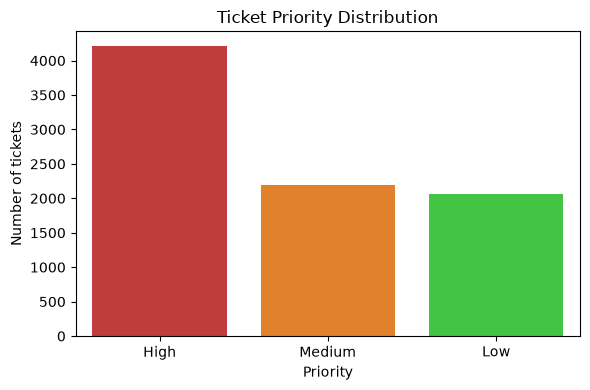

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["High", "Medium", "Low"]
colors = {"High" : "#d62728", "Medium": "#ff7f0e", "Low" : "#2eda2e"}
sns.countplot(
            data=data,
            x=PRIORITY_COL,
            order=order,
            hue=PRIORITY_COL,
            palette=colors,
            legend=False,
            ax = ax)

ax.set_title("Ticket Priority Distribution")
ax.set_xlabel("Priority")
ax.set_ylabel("Number of tickets")
plt.tight_layout()
plt.savefig(f"outputs/Priority_distribution.png", dpi=200)
plt.show()

In [28]:
def clean_text(text):
    text = str(text).lower()
    tokens = tokenizer.tokenize(text)                
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 2]
    tokens = [lemmatize(t) for t in tokens]
    return " ".join(tokens)

data["clean_text"] = data["raw_text"].apply(clean_text)
data = data[data["clean_text"].str.len() > 0].reset_index(drop=True)

# Pehle aur baad ka comparison
for i in range(5):
    print("BEFORE:", data.loc[i, "raw_text"][:150])
    print("AFTER :", data.loc[i, "clean_text"][:150])
    print()

BEFORE: Product setup I'm having an issue with the . Please assist. Your billing zip code is: 71701. We appreciate that you have requested a website address. 
AFTER : product setup issue please assist billing zip code appreciate requested website address please double check email address tried troubleshooting step m

BEFORE: Peripheral compatibility I'm having an issue with the . Please assist. If you need to change an existing product. I'm having an issue with the . Pleas
AFTER : peripheral compatibility issue please assist need change existing product issue please assist issue facing intermittent sometimes work fine time act u

BEFORE: Network problem I'm facing a problem with my . The is not turning on. It was working fine until yesterday, but now it doesn't respond. 1.8.3 I really 
AFTER : network problem facing problem not turning working fine yesterday respond really using original charger came not charging properly

BEFORE: Account access I'm having an issue with the . Please as

In [29]:
idx_train, idx_test = train_test_split(
    data.index, test_size= TEST_SIZE, random_state=RANDOM_STATE, stratify= data[CATEGORY_COL]
)

x_train, x_test = data.loc[idx_train, CATEGORY_COL], data.loc[idx_test, "clean_text"]
raw_test = data.loc[idx_test, "raw_text"]

yc_train, yc_test = data.loc[idx_train,CATEGORY_COL], data.loc[idx_test, CATEGORY_COL]
yp_train, yp_test = data.loc[idx_train,PRIORITY_COL], data.loc[idx_test, PRIORITY_COL]

print("Train_tickets:", len(x_train), "| Test tickets:", len(x_test) )

Train_tickets: 6775 | Test tickets: 1694


In [30]:
def build_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "Naive Bayes" : MultinomialNB(),
        "Linear SVM" : LinearSVC(class_weight="balanced")
    }

def make_pipeline(model):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df = 2, sublinear_tf = True, max_features = 20000)),
        ("clf", model),
    ])

def score(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average = "weighted", zero_division = 0),
        "Recall": recall_score(y_true, y_pred, average = "weighted", zero_division = 0),
        "F1": f1_score(y_true, y_pred, average = "weighted", zero_division = 0)
    }

def train_and_compare(y_train, y_test):
    fitted, rows = {}, []
    for name, model in build_models().items():
        pipe = make_pipeline(model).fit(x_train , y_train)
        pred = pipe.predict(x_test)
        fitted[name] = pipe
        rows.append({"Model": name, **score(y_test, pred)})

    table = pd.DataFrame(rows).set_index("Model").round(3)
    return fitted, table

cat_models, cat_results =  train_and_compare(yc_train, yc_test)
best_cat = cat_results["F1"].idxmax()
print("CATRGORY results")
display(cat_results)
print("Best category model: ", best_cat)

CATRGORY results


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.199,0.254,0.199,0.140
Naive Bayes,0.196,0.247,0.196,0.145
Linear SVM,0.198,0.254,0.198,0.139


Best category model:  Naive Bayes


In [31]:
pri_models, pri_results = train_and_compare(yp_train, yp_test)
best_pri = pri_results["F1"].idxmax()
print("PRIORITY results (sirf ML ke bina)")
display(pri_results)
print("Best priority model:", best_pri)

PRIORITY results (sirf ML ke bina)


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.459,0.365,0.459,0.377
Naive Bayes,0.511,0.261,0.511,0.345
Linear SVM,0.511,0.261,0.511,0.345


Best priority model: Logistic Regression


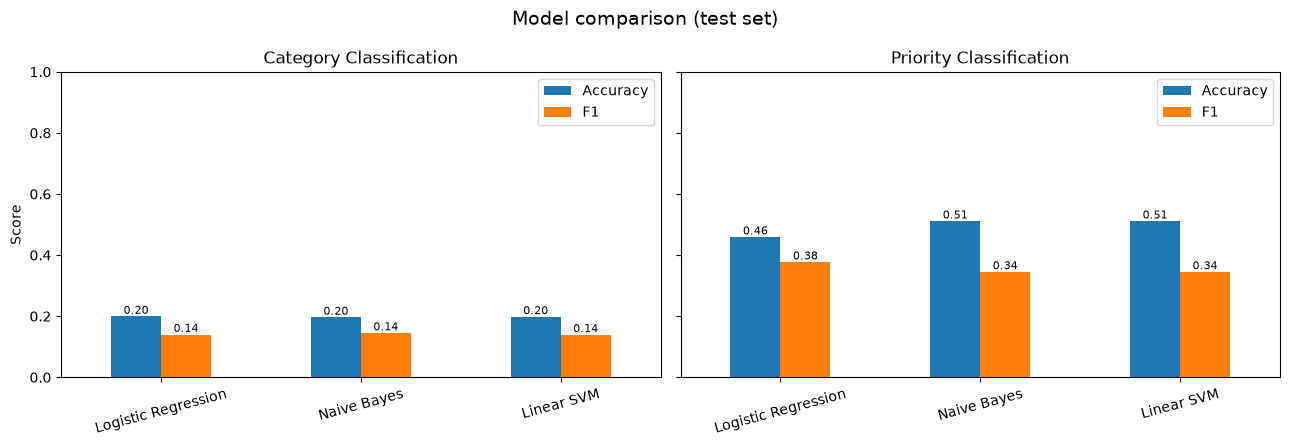

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey = True)
for ax, table, title in [(axes[0], cat_results, "Category Classification"),
                         (axes[1], pri_results, "Priority Classification")]:
    
    table[["Accuracy", "F1"]].plot(kind="bar", ax=ax, color=["#1f77b4", "#ff7f0e"], rot = 15)

    ax.set_xlabel("")
    ax.set_title(title)
    ax.set_ylim(0, 1)

    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize = 8)

axes[0].set_ylabel("Score")
plt.suptitle("Model comparison (test set)", fontsize = 14)
plt.tight_layout()
plt.savefig(f"outputs/model_comparison.png", dpi = 200)
plt.show()

Best category model: Naive Bayes
Accuracy: 0.196

                      precision    recall  f1-score   support

     Billing inquiry       0.50      0.00      0.01       327
Cancellation request       0.17      0.06      0.09       339
     Product inquiry       0.17      0.19      0.18       328
      Refund request       0.19      0.10      0.13       351
     Technical issue       0.21      0.61      0.31       349

            accuracy                           0.20      1694
           macro avg       0.25      0.19      0.14      1694
        weighted avg       0.25      0.20      0.15      1694



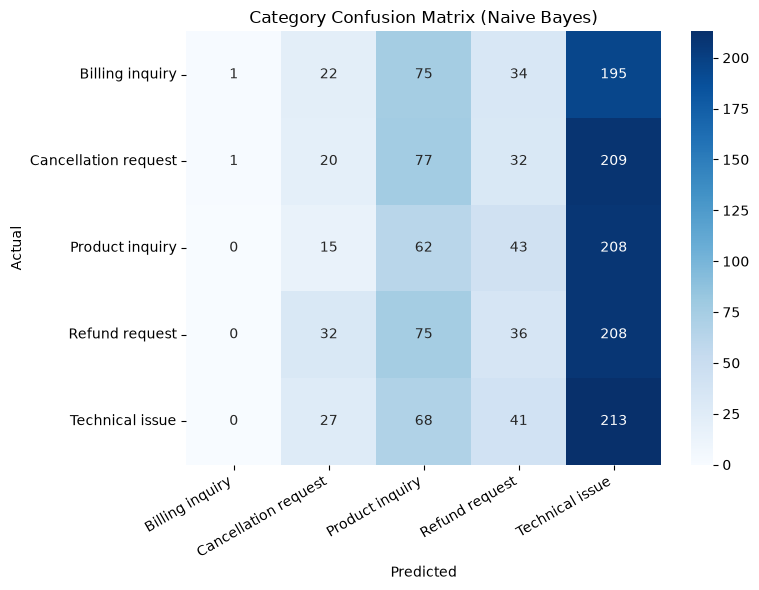

In [33]:
best_cat_pipe = cat_models[best_cat]
pred_cat = best_cat_pipe.predict(x_test)

print(f"Best category model: {best_cat}")
print(f"Accuracy: {accuracy_score(yc_test, pred_cat):.3f}\n")
print(classification_report(yc_test, pred_cat, zero_division=0))

labels = sorted(data[CATEGORY_COL].unique())
cm = confusion_matrix(yc_test, pred_cat, labels=labels)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title(f"Category Confusion Matrix ({best_cat})")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"outputs/confusion_matrix_category.png", dpi=200)
plt.show()

In [34]:
import re 
HIGH_KEYWORDS = [
   
    "down", "outage", "not working", "crash",
    
    "payment failed", "charged twice", "hacked", "unauthorized",
 
    "urgent", "asap", "immediately", "critical",
]
rule_pattern = re.compile("|".join(r"\b" + re.escape(k) for k in HIGH_KEYWORDS))

def needs_escalation(raw_text):
    return bool(rule_pattern.search(str(raw_text).lower()))

def final_priority(ml_pred, raw_texts):
    flags = np.array([needs_escalation(t) for t in raw_texts])
    out = np.where(flags, "High", ml_pred) if USE_RULES else np.array(ml_pred)
    return out, flags

best_pri_pipe = pri_models[best_pri]
pred_pri_ml = best_pri_pipe.predict(x_test)
pred_pri_final, flags = final_priority(pred_pri_ml, raw_test)

print(f"Best priority model: {best_pri}")
print(f"Tickets escalated by rules: {flags.sum()} of {len(flags)} ({flags.mean()*100:.1f}%)\n")

compare = pd.DataFrame({
    "ML only": score(yp_test, pred_pri_ml),
    "ML + rules": score(yp_test, pred_pri_final),
}).T
compare["High recall"] = [
    recall_score(yp_test, p, labels=["High"], average=None, zero_division=0)[0]
    for p in (pred_pri_ml, pred_pri_final)
]
display(compare.round(3))

Best priority model: Logistic Regression
Tickets escalated by rules: 169 of 1694 (10.0%)



,Accuracy,Precision,Recall,F1,High recall
ML only,0.459,0.365,0.459,0.377,0.821
ML + rules,0.468,0.360,0.468,0.375,0.850


Final priority system (USE_RULES = True)

              precision    recall  f1-score   support

        High       0.51      0.85      0.64       865
      Medium       0.26      0.11      0.15       454
         Low       0.13      0.02      0.04       375

    accuracy                           0.47      1694
   macro avg       0.30      0.33      0.28      1694
weighted avg       0.36      0.47      0.37      1694



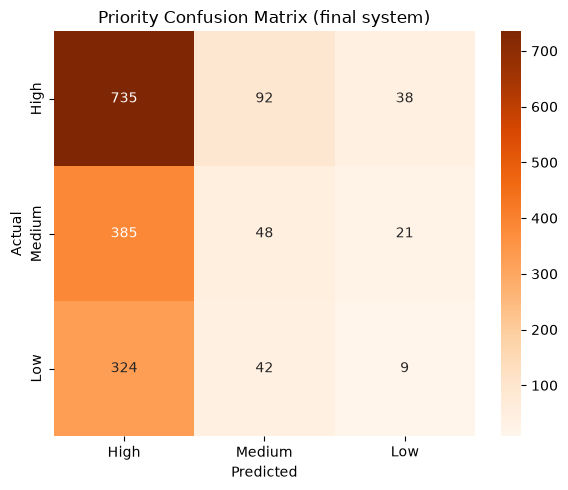

In [23]:
print(f"Final priority system (USE_RULES = {USE_RULES})\n")
print(classification_report(yp_test, pred_pri_final, labels=["High", "Medium", "Low"], zero_division=0))

p_labels = ["High", "Medium", "Low"]
cm = confusion_matrix(yp_test, pred_pri_final, labels=p_labels)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", xticklabels=p_labels, yticklabels=p_labels, ax=ax)
ax.set_title("Priority Confusion Matrix (final system)")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(f"outputs/confusion_matrix_priority.png", dpi=200)
plt.show()

In [24]:
lr_pipe = cat_models["Logistic Regression"]
tfidf = lr_pipe.named_steps["tfidf"]
clf = lr_pipe.named_steps["clf"]
words = np.array(tfidf.get_feature_names_out())

for i, cls in enumerate(clf.classes_):
    top = words[np.argsort(clf.coef_[i])[-8:][::-1]]
    print(f"{cls:25s}: {', '.join(top)}")

Billing inquiry          : billing inquiry, billing, inquiry, refund request, refund, cancellation request, cancellation, technical issue
Cancellation request     : cancellation, cancellation request, request, product, product inquiry, billing inquiry, billing, technical
Product inquiry          : product inquiry, product, inquiry, refund request, refund, cancellation, cancellation request, technical issue
Refund request           : refund, refund request, request, product, product inquiry, billing inquiry, billing, technical
Technical issue          : technical issue, technical, issue, product inquiry, product, billing inquiry, billing, refund request


In [25]:
def confidence(pipe, texts):
    clf = pipe.named_steps["clf"]
    Xv = pipe.named_steps["tfidf"].transform(texts)
    if hasattr(clf, "predict_proba"):
        return clf.predict_proba(Xv).max(axis=1)
    scores = clf.decision_function(Xv)
    if scores.ndim == 1:
        scores = np.column_stack([-scores, scores])
    e = np.exp(scores - scores.max(axis=1, keepdims=True))
    return (e / e.sum(axis=1, keepdims=True)).max(axis=1)

predictions = pd.DataFrame({
    "ticket_text": raw_test.str[:200].values,
    "actual_category": yc_test.values,
    "predicted_category": pred_cat,
    "category_confidence": confidence(best_cat_pipe, x_test).round(3),
    "actual_priority": yp_test.values,
    "ml_priority": pred_pri_ml,
    "final_priority": pred_pri_final,
    "escalated_by_rule": flags,
})
predictions["category_correct"] = predictions["actual_category"] == predictions["predicted_category"]
predictions.to_csv(f"outputs/predictions.csv", index=False)

print("Saved:", f"outputs/predictions.csv", "| rows:", len(predictions))
predictions.head()

Saved: outputs/predictions.csv | rows: 1694


,ticket_text,actual_category,predicted_category,category_confidence,actual_priority,ml_priority,final_priority,escalated_by_rule,category_correct
0,Installation support I'm having an issue with ...,Product inquiry,Technical issue,0.995,Low,High,High,False,False
1,Refund request I'm having an issue with the . ...,Refund request,Refund request,0.950,High,Low,Low,False,True
2,Cancellation request I'm having an issue with ...,Billing inquiry,Cancellation request,0.997,Low,Medium,Medium,False,False
3,Account access I'm having an issue with the . ...,Product inquiry,Product inquiry,0.970,Medium,Medium,Medium,False,True
4,Cancellation request I'm having an issue with ...,Refund request,Cancellation request,0.997,High,Medium,Medium,False,False


In [26]:
def predict_ticket(text):
    """Ek naye ticket ka category aur priority batata hai."""
    clean = clean_text(text)
    cat = best_cat_pipe.predict([clean])[0]
    conf = confidence(best_cat_pipe, [clean])[0]
    ml_pri = best_pri_pipe.predict([clean])[0]
    pri, flag = final_priority(np.array([ml_pri]), [text])
    return {"category": str(cat), "confidence": round(float(conf), 2),
            "priority": str(pri[0]), "escalated_by_rule": bool(flag[0])}

samples = [
    "URGENT: our whole account is down and the app is not working since morning!",
    "I was charged twice for my subscription, please refund the extra payment.",
    "How do I change the colour theme in the settings? Just a general question.",
    "I forgot my password and cannot login to my account.",
]
for s in samples:
    print(s)
    print("   :", predict_ticket(s), "\n")

URGENT: our whole account is down and the app is not working since morning!
   : {'category': 'Refund request', 'confidence': 0.21, 'priority': 'High', 'escalated_by_rule': True} 

I was charged twice for my subscription, please refund the extra payment.
   : {'category': 'Refund request', 'confidence': 1.0, 'priority': 'High', 'escalated_by_rule': True} 

How do I change the colour theme in the settings? Just a general question.
   : {'category': 'Refund request', 'confidence': 0.21, 'priority': 'High', 'escalated_by_rule': False} 

I forgot my password and cannot login to my account.
   : {'category': 'Refund request', 'confidence': 0.21, 'priority': 'High', 'escalated_by_rule': False} 



In [27]:
cat_rep = classification_report(yc_test, pred_cat, output_dict=True, zero_division=0)
cat_recall = {k: v["recall"] for k, v in cat_rep.items() if k in labels}
easiest = max(cat_recall, key=cat_recall.get)
hardest = min(cat_recall, key=cat_recall.get)

# Sabse zyada confuse hone wali jodi
cm_off = confusion_matrix(yc_test, pred_cat, labels=labels).astype(float)
np.fill_diagonal(cm_off, 0)
i, j = np.unravel_index(cm_off.argmax(), cm_off.shape)

high_share = (data[PRIORITY_COL] == "High").mean() * 100
high_recall = recall_score(yp_test, pred_pri_final, labels=["High"], average=None, zero_division=0)[0]
low_conf = (predictions["category_confidence"] < 0.5).mean() * 100

print("=" * 62)
print("SUPPORT TICKET CLASSIFICATION")
print("=" * 62)
print(f"Tickets used               : {len(data)}")
print(f"Best category model        : {best_cat}  (accuracy {accuracy_score(yc_test, pred_cat)*100:.1f}%, F1 {f1_score(yc_test, pred_cat, average='weighted')*100:.1f}%)")
print(f"Easiest category (recall)  : {easiest}  ({cat_recall[easiest]*100:.1f}%)")
print(f"Hardest category (recall)  : {hardest}  ({cat_recall[hardest]*100:.1f}%)")
print(f"Most confused pair         : actual '{labels[i]}' predicted as '{labels[j]}'  ({int(cm_off[i, j])} tickets)")
print(f"High priority share        : {high_share:.1f}% of tickets")
print(f"High priority recall       : {high_recall*100:.1f}%  (final system)")
print()

SUPPORT TICKET CLASSIFICATION
Tickets used               : 8469
Best category model        : Naive Bayes  (accuracy 19.6%, F1 14.5%)
Easiest category (recall)  : Technical issue  (61.0%)
Hardest category (recall)  : Billing inquiry  (0.3%)
Most confused pair         : actual 'Cancellation request' predicted as 'Technical issue'  (209 tickets)
High priority share        : 49.8% of tickets
High priority recall       : 85.0%  (final system)

